# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import S2CloudMaskCatalogueDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/s2cmc"
}
dataset = S2CloudMaskCatalogueDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 513


# Show images

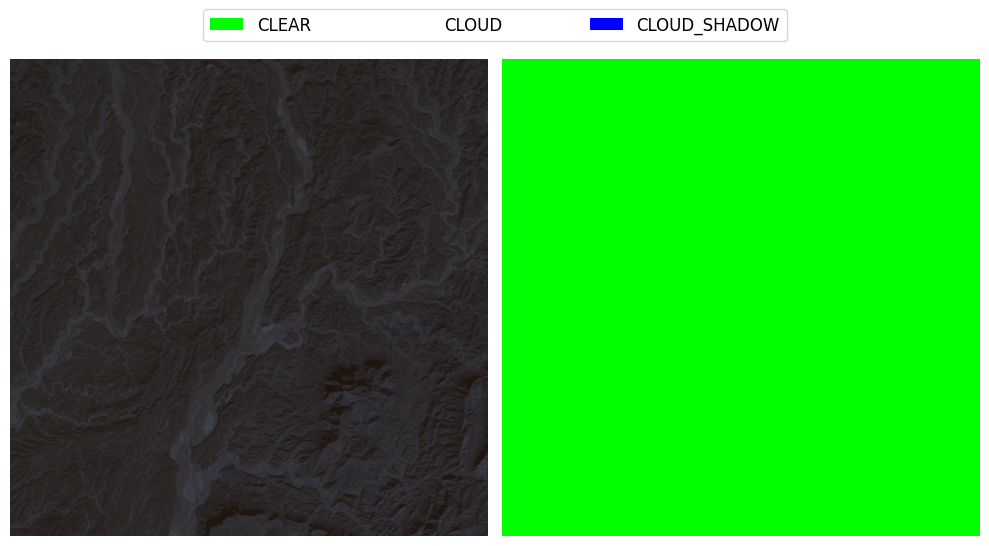

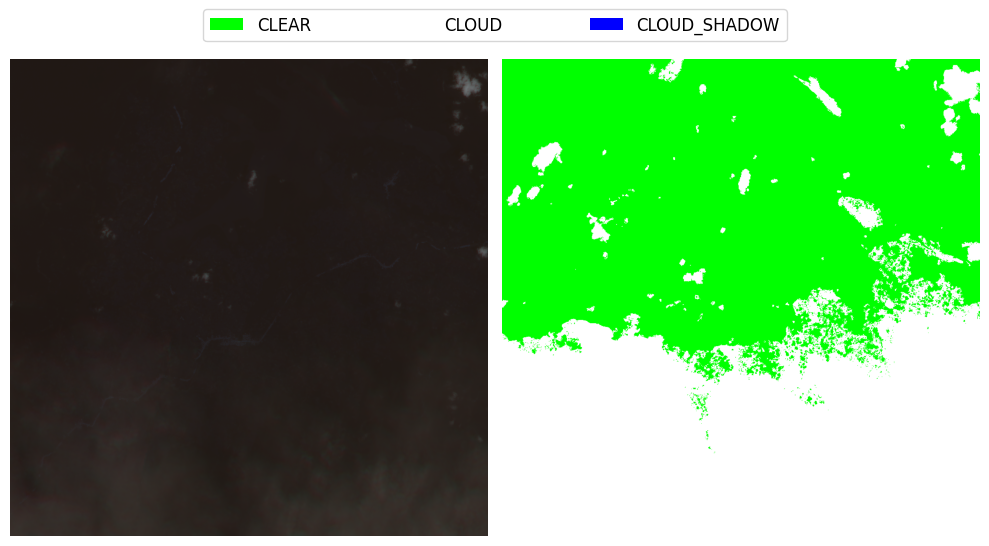

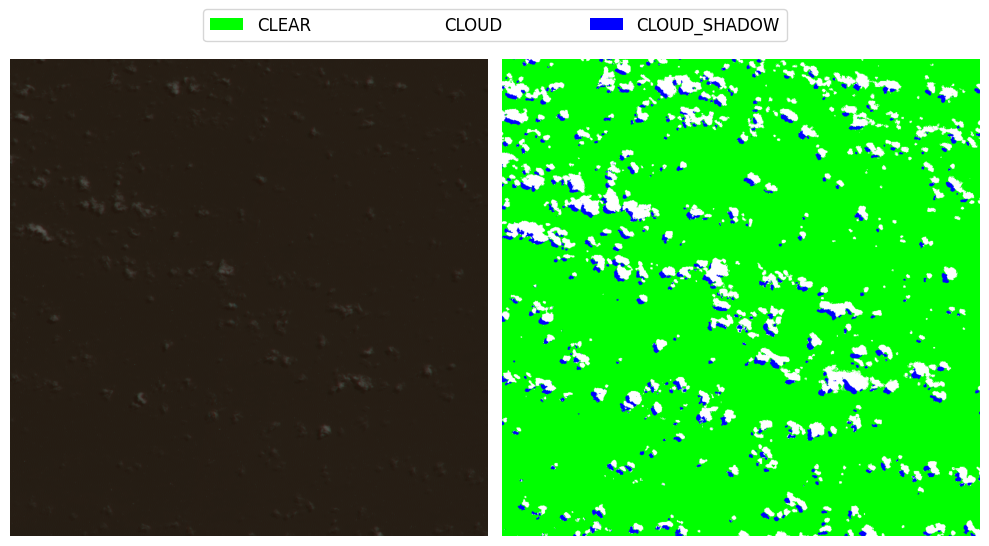

In [56]:
dataset.show_image(10)
dataset.show_image(150)
dataset.show_image(200);

In [64]:
dataset.data_distribution_table()

,Number of pixels
CLEAR,246237165
CLOUD,281726534
CLOUD_SHADOW,7856593


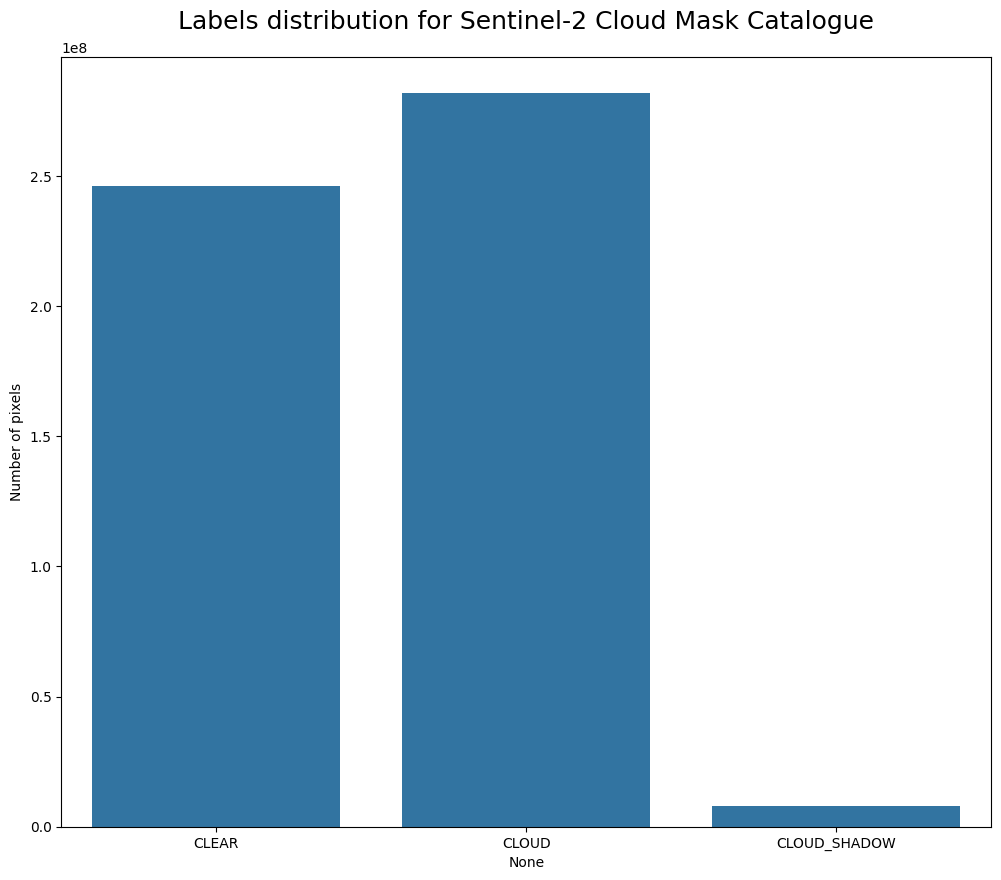

In [65]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/s2cmc",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = S2CloudMaskCatalogueDataset(train_dataset_config)
len(train_dataset)

410

## Create the model ##

In [20]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/s2cmc"
model_config = {
    "num_classes": 3, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [21]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-04 11:57:16,850 INFO Starting training.
training: 100%|██████████| 52/52 [00:05<00:00, 10.34it/s]
2025-09-04 11:57:21,964 INFO epoch: 1, time: 5, loss:  0.55059
testing on train set: 100%|██████████| 52/52 [00:04<00:00, 12.54it/s]
2025-09-04 11:57:28,034 INFO IOU:0.45528633744347974, IOU mean:0.3048623874825806, IOU per Class:[0.42945218 0.48513498 0.        ]
training: 100%|██████████| 52/52 [00:04<00:00, 10.45it/s]
2025-09-04 11:57:33,016 INFO epoch: 2, time: 5, loss:  0.49791
testing on train set: 100%|██████████| 52/52 [00:04<00:00, 12.94it/s]
2025-09-04 11:57:37,047 INFO IOU:0.4646883816969955, IOU mean:0.3116146549591326, IOU per Class:[4.51005980e-01 4.83672758e-01 1.65227390e-04]
training: 100%|██████████| 52/52 [00:05<00:00, 10.10it/s]
2025-09-04 11:57:42,203 INFO epoch: 3, time: 5, loss:  0.46743
testing on train set: 100%|██████████| 52/52 [00:04<00:00, 12.76it/s]
2025-09-04 11:57:46,294 INFO IOU:0.46868075748314303, IOU mean:0.3132821800260035, IOU per Class:[0.4477

0.3453583510910592

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/s2cmc",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = S2CloudMaskCatalogueDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/s2cmc/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

51


2025-09-04 12:00:29,202 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/s2cmc/checkpoint.pth.tar
2025-09-04 12:00:29,672 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/s2cmc/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 13/13 [00:00<00:00, 13.27it/s]


[{'IOU': 0.47790842782367743,
  'IOU mean': 0.3182566157751921,
  'IOU per Class': array([0.42818455, 0.5265853 , 0.        ])}]

## Predictions

2025-09-04 12:00:54,540 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/s2cmc/checkpoint.pth.tar
2025-09-04 12:00:54,899 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/s2cmc/checkpoint.pth.tar at epoch 21


52


2025-09-04 12:00:55,311 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


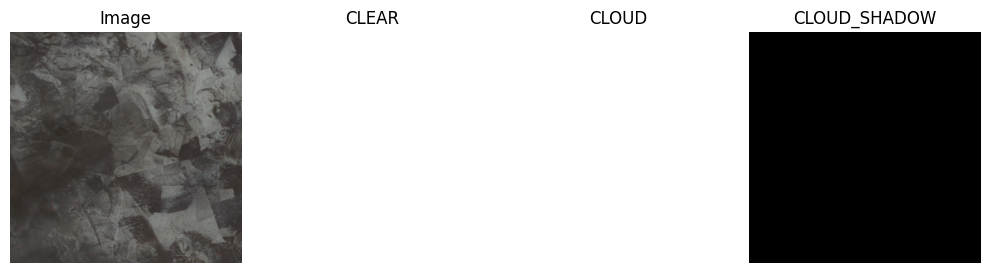

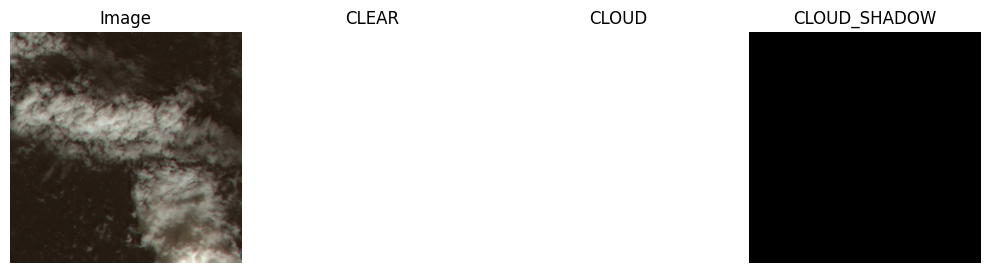

In [ ]:
model_path = "/home/dragik/data/FAIR_EO/experiments/s2cmc/checkpoint.pth.tar"
labels = ["CLEAR", "CLOUD", "CLOUD_SHADOW"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/s2cmc",
    "mode": "test"
}

test_dataset = S2CloudMaskCatalogueDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)